In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats
import torch
from utils import block_diag

In [2]:
N = 256

freqs = np.array([np.pi/3*i for i in range(N)])
freqs.shape

(256,)

In [3]:

# p0 = p0[keys]
lx = np.cos(freqs)
ly = np.sin(freqs)



u = (torch.rand((N, N)).to(torch.float32) - 0.5)*2 # random
Gr = u - u.T # skew symmetric
R = torch.matrix_exp(Gr) # orthogonal, s = 1

p0 = R.T@torch.tensor(np.ones(len(R)).astype(np.float32))
p0 = p0.numpy()
c = torch.ones(N)

(np.float64(-1.1),
 np.float64(1.1),
 np.float64(-0.9526279441629026),
 np.float64(0.9526279441629051))

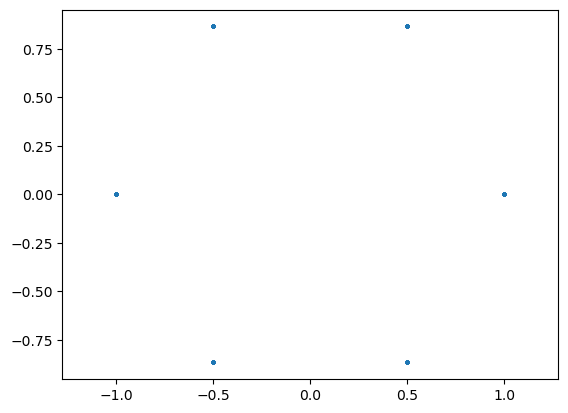

In [4]:
plt.scatter(lx, ly, s = 3)
plt.axis("equal")

In [5]:
a = 20
x = np.linspace(-a, a, 100)
y = np.linspace(-a, a, 100)
X, Y = np.meshgrid(x, y)
xx = X.flatten()
yy = Y.flatten()

s = np.sum((p0[None])**2*np.cos(lx[None]*xx[:,None] + ly[None]*yy[:,None]), axis = -1)
s = np.real(s)

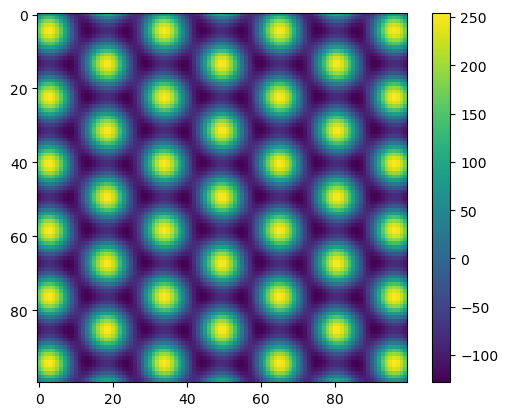

In [6]:
plt.imshow(s.reshape(100,100))
plt.colorbar()

In [7]:
Sx = block_diag(lx[:len(lx)//2])
Sy = block_diag(ly[:len(ly)//2])

In [ ]:
Sxplus = block_diag(l_plusx)
Syplus = block_diag(l_plusy)
Sxminus = block_diag(l_minusx)
Syminus = block_diag(l_minusy)

In [ ]:
torch.save(Sxplus, "sigma_A.pt")
torch.save(Syplus, "sigma_B.pt")
torch.save(Gr, "Gr.pt")
torch.save(p0, "p0.pt")